In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings
warnings.filterwarnings('ignore')

In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
df=pd.read_csv("loan_approved.csv")

In [3]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [4]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
df.isnull().sum()


Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

### Imputing the null values

In [6]:
df['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [7]:
# we have imputed the null values
df.loc[df['Gender'].isnull(),'Gender']="Male"

In [8]:
df.Gender.isnull().sum()

np.int64(0)

In [9]:
df['Credit_History'].value_counts()

Credit_History
1.0    475
0.0     89
Name: count, dtype: int64

In [10]:
#we have imputed the null values with the 0
df.loc[df['Credit_History'].isnull(),'Credit_History']=0.0

In [11]:
df.Gender.isnull().sum()

np.int64(0)

In [12]:
#we have imputed the null values with the median
df.loc[df['LoanAmount'].isnull(),'LoanAmount']=df['LoanAmount'].median()

In [13]:
df.LoanAmount.isnull().sum()

np.int64(0)

In [14]:
df['Self_Employed'].value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [15]:
df.loc[df['Self_Employed'].isnull(),'Self_Employed']="No"

In [16]:
df.Self_Employed.isnull().sum()

np.int64(0)

In [17]:
df['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [18]:
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=360.0

In [19]:
df.Loan_Amount_Term.isnull().sum()

np.int64(0)

In [20]:
df['Dependents'].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [21]:
df.loc[df['Dependents'].isnull(),'Dependents']="0"

In [22]:
df.Dependents.isnull().sum()

np.int64(0)

In [23]:
df['Married'].value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [24]:
df.loc[df['Married'].isnull(),'Married']="Yes"

In [25]:
df.Married.isnull().sum()

np.int64(0)

In [26]:
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   0
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

## Handling Outliers

### Using Winsorize Method  to handle outliers:

<Axes: xlabel='ApplicantIncome'>

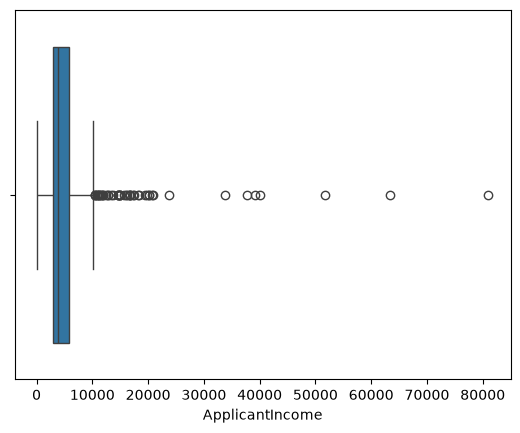

In [27]:
sns.boxplot(x=df.ApplicantIncome ,orient='h')


<Axes: xlabel='LoanAmount'>

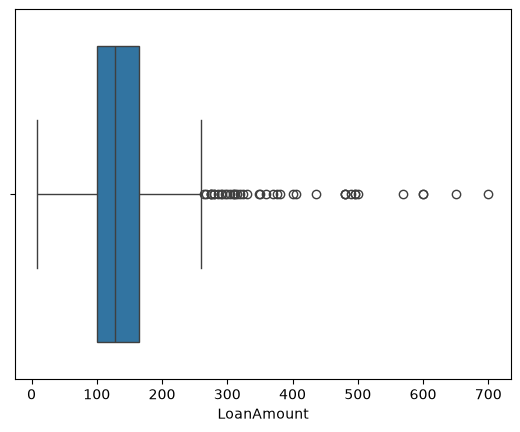

In [28]:
sns.boxplot(x=df.LoanAmount ,orient='h')

In [29]:
from scipy.stats.mstats import winsorize

#Specify the % of data to be trimmed from both ends
trim_percentage=0.08

#winsorize the specified column
df['ApplicantIncome']=winsorize(df['ApplicantIncome'],limits=trim_percentage)

<Axes: xlabel='ApplicantIncome'>

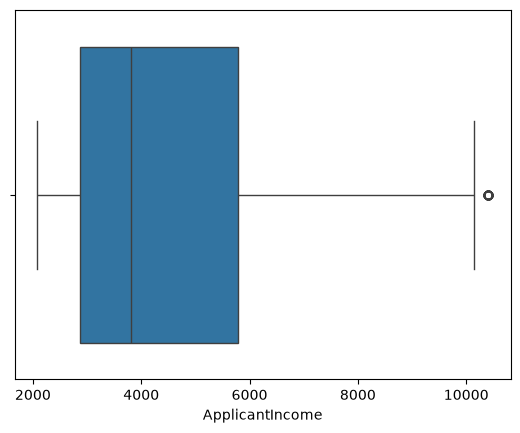

In [30]:
sns.boxplot(x=df.ApplicantIncome ,orient='h')

### Using IQR Method  to handle outliers:

In [31]:
#calculate Quartiles
Q1=df['LoanAmount'].quantile(0.25)
Q3=df['LoanAmount'].quantile(0.75)

In [32]:
#calculate IQR
IQR=Q3-Q1
IQR

np.float64(64.5)

In [33]:
# Define lower & upper bounds
lower_bounds=Q1-1.5*IQR
upper_bounds=Q3+1.5*IQR

In [34]:
print(lower_bounds)
print(upper_bounds)

3.5
261.5


In [35]:
#Remove outliers
df=df[(df['LoanAmount']>=lower_bounds)&(df['LoanAmount']<=upper_bounds)]

<Axes: xlabel='LoanAmount'>

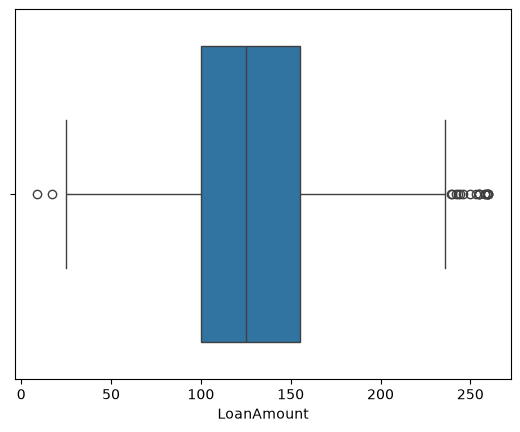

In [36]:
sns.boxplot(x=df.LoanAmount,orient='h')

## Encoding Technique

### using one Hot Encoding

In [37]:
df_encoded=pd.get_dummies(df,columns=['Married'],prefix='Married')

In [38]:
df_encoded.columns

Index(['Loan_ID', 'Gender', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'Married_No', 'Married_Yes'],
      dtype='str')

### using  label Encoding

In [39]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

#Fit & transform the 'matchType' column to obtain label-encoded values
df['Married']=encoder.fit_transform(df['Married'])

#Display the result
print(df[['Married']])


     Married
0          0
1          1
2          1
3          1
4          0
..       ...
609        0
610        1
611        1
612        1
613        0

[573 rows x 1 columns]


In [40]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

#Fit & transform the 'matchType' column to obtain label-encoded values
df['Loan_Status (Approved)']=encoder.fit_transform(df['Loan_Status (Approved)'])

#Display the result
print(df[['Loan_Status (Approved)']])


     Loan_Status (Approved)
0                         1
1                         0
2                         1
3                         1
4                         1
..                      ...
609                       1
610                       1
611                       1
612                       1
613                       0

[573 rows x 1 columns]


### using  Ordinal Encoding

In [41]:
df.Education.value_counts()

Education
Graduate        440
Not Graduate    133
Name: count, dtype: int64

In [42]:
Education_enc=OrdinalEncoder(categories=[['Graduate','Not Graduate']])

In [43]:
df['Education']=encoder.fit_transform(df[['Education']])

In [44]:
df.Education.value_counts()

Education
0    440
1    133
Name: count, dtype: int64

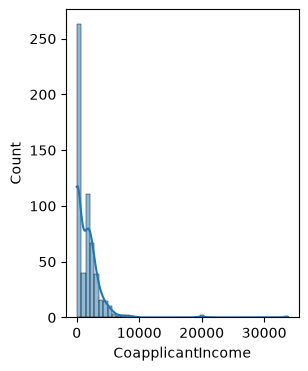

In [45]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'], kde=True)
plt.show()

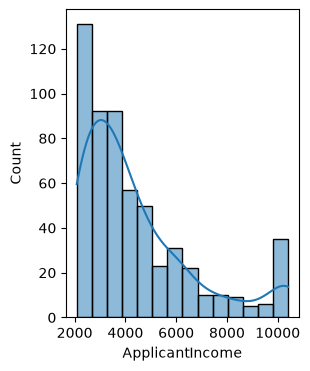

In [46]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'], kde=True)
plt.show()

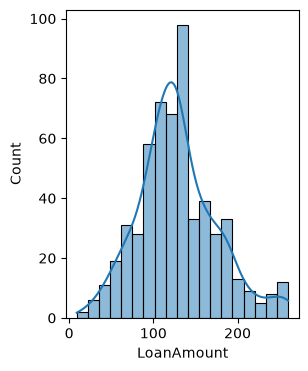

In [47]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'], kde=True)
plt.show()

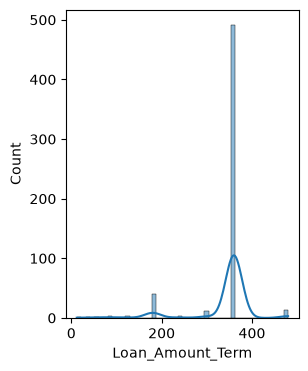

In [48]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['Loan_Amount_Term'], kde=True)
plt.show()

### Using log Transformation:

In [49]:
df['CoapplicantIncome']=np.log(df['CoapplicantIncome'])

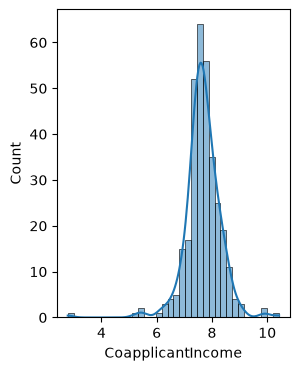

In [50]:

plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'], kde=True)  # Target Column
plt.show()

### Using Exponential Transformation:

In [51]:
df['ApplicantIncome_exponential']=df.ApplicantIncome**(1/1.2)

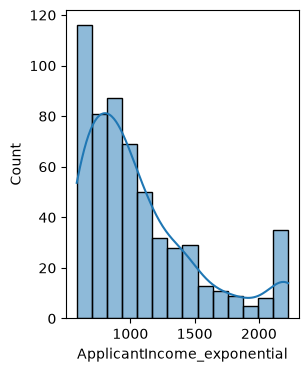

In [52]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome_exponential'], kde=True)  
plt.show()

### Using Square Root Transformation:

In [53]:
df['LoanAmount']=df.LoanAmount**(1/2)

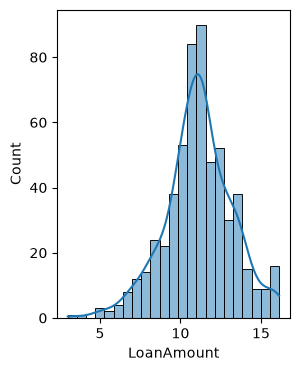

In [54]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'], kde=True)  
plt.show()

### Using Box cox Transformation:

In [55]:
from scipy.stats import boxcox
transformed_data,lambda_value=boxcox(df['Loan_Amount_Term'])

In [56]:
print("Lambda value:",lambda_value)

Lambda value: 3.0185540252193874


## Scalling Techniques

### Using Standard Scalar:

In [57]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'ApplicantIncome_exponential'],
      dtype='str')

In [61]:

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
ApplicantIncome_scaled=scaler.fit_transform(df[['ApplicantIncome']])


In [62]:
ApplicantIncome_scaled

array([[ 6.56101241e-01],
       [ 8.78211459e-02],
       [-6.22753412e-01],
       [-8.09935718e-01],
       [ 7.23881884e-01],
       [-9.22155326e-01],
       [-6.06593788e-01],
       [-1.71181709e-01],
       [-5.32977725e-01],
       [-8.47192628e-01],
       [-5.89985286e-01],
       [-1.03437493e+00],
       [-1.03437493e+00],
       [ 2.52559530e-01],
       [-3.55221866e-01],
       [-3.93825411e-01],
       [ 2.24280189e-01],
       [-8.02304784e-01],
       [ 1.46902008e+00],
       [-8.02304784e-01],
       [-4.58912784e-01],
       [-3.00907576e-01],
       [ 2.32188910e+00],
       [-7.12977976e-01],
       [-7.24284543e-02],
       [-1.03437493e+00],
       [-2.86094588e-01],
       [-9.93611602e-02],
       [-5.47790714e-01],
       [ 1.36748895e-01],
       [-3.98314196e-01],
       [-9.48190275e-01],
       [-1.03437493e+00],
       [-3.23351498e-01],
       [-9.93611602e-02],
       [-2.86992345e-01],
       [-3.53426353e-01],
       [-1.03437493e+00],
       [-8.9

###  Using MinMax Scaling

In [63]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
ApplicantIncome_scaled2=scaler.fit_transform(df[['ApplicantIncome']])

### Robust Scalar:

In [64]:
from sklearn.preprocessing import RobustScaler
scaler=RobustScaler()
ApplicantIncome_scaled2=scaler.fit_transform(df[['ApplicantIncome']])